In [130]:
from captum.attr import configure_interpretable_embedding_layer, remove_interpretable_embedding_layer
from captum.attr import LayerIntegratedGradients, LayerGradientXActivation
from config import get_model_config
from models.interpretability import CaseTransformerInterpretability, CaptumWrapper
from models.transformer_helpers import encode_month_year_features, bond_one_hot, discretize_bond_amount
from models.transformer_model import CaseTransformerModel
from pathlib import Path
from transformers import AutoModel, AutoTokenizer
from typing import Dict, List, Tuple, Optional, Any, Union
from utils.cache_directory_utils import CacheDirectoryManager
import matplotlib.pyplot as plt
import numpy as np
import pickle
import seaborn as sns
import sys
import torch
import torch.nn as nn
import pandas as pd
import nltk
import string

In [131]:
try:
    from nltk.corpus import stopwords
    stop_words = set(stopwords.words('english'))
except LookupError:
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    stop_words = set(stopwords.words('english'))

In [132]:
import os
import json
from pathlib import Path

parameters_filename = 'balanced_config_9.json'
PROJECT_ROOT = Path("/home/krosen5/Court Case Sequence Transformer Model/court_case_transformer_project")
parameters_path = PROJECT_ROOT / "parameters_jsons" / parameters_filename
with open(parameters_path, "r", encoding="utf-8") as file:
    parameters_dict = json.load(file)

In [133]:
def load_model_for_captum(
    model_cache_manager: CacheDirectoryManager,
    model_name="final_model",
    device=None,
    verbose=True
):
    model_dir = model_cache_manager.get_cache_dir('exported_models')
    
    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
    print("="*70)
    print("LOADING MODEL FOR CAPTUM INTERPRETABILITY")
    print("="*70)
    print(f"Model directory: {model_dir}")
    print(f"Device: {device}")
    print(f"Verbose mode: {verbose}")
    print()
    
    # 1. Load model configuration
    config_path = model_dir / 'model_config.pkl'
    if not config_path.exists():
        raise FileNotFoundError(f"Model config not found: {config_path}")
    
    with open(config_path, 'rb') as f:
        config_dict = pickle.load(f)
    print(f"✅ Loaded model configuration")
    
    # 2. Update global config
    model_config = get_model_config()
    if config_dict['min_year'] != model_config.min_year or config_dict['max_year'] != model_config.max_year:
        model_config.update_date_range(config_dict['min_year'], config_dict['max_year'])
    
    # 3. Load vocabularies
    charge_vocab_path = model_dir / 'charge_vocab.pkl'
    with open(charge_vocab_path, 'rb') as f:
        charge_vocab = pickle.load(f)
    print(f"✅ Loaded charge vocabulary (size: {charge_vocab.size})")
    
    mag_vocab_path = model_dir / 'mag_vocab.pkl'
    with open(mag_vocab_path, 'rb') as f:
        mag_vocab = pickle.load(f)
    print(f"✅ Loaded magistrate vocabulary (size: {mag_vocab.size})")
    
    # 4. Load label processor
    label_processor_path = model_dir / 'label_processor.pkl'
    with open(label_processor_path, 'rb') as f:
        label_processor = pickle.load(f)
    print(f"✅ Loaded label processor ({len(label_processor.label_names)} labels)")
    
    # 5. Check BERT cache
    bert_cache_dir = model_cache_manager.get_cache_dir('bert')
    if not bert_cache_dir.exists():
        raise FileNotFoundError(
            f"BERT cache directory not found: {bert_cache_dir}\n"
            "Captum analysis requires BERT embeddings to be available."
        )
    print(f"✅ Found BERT cache: {bert_cache_dir}")
    
    # 6. Create model with interpretability enabled
    print("\n🔧 Creating model architecture...")
    model = CaseTransformerModel(
        charge_vocab=charge_vocab,
        mag_vocab=mag_vocab,
        bert_cache_dir=bert_cache_dir,
        num_labels=config_dict['num_labels'],
        hidden_dim=config_dict['hidden_dim'],
        max_len=config_dict['max_len'],
        bond_dim=config_dict['bond_dim'],
        temporal_dim=config_dict['temporal_dim'],
        enable_interpretability=True  # IMPORTANT: Enable for Captum,
    )
    
    # 7. Load weights
    model_weights_path = model_dir / f"{model_name}.pt"
    if not model_weights_path.exists():
        raise FileNotFoundError(f"Model weights not found: {model_weights_path}")
    
    state_dict = torch.load(model_weights_path, map_location=device)
    model.load_state_dict(state_dict)
    model = model.to(device)
    model.eval()
    print(f"✅ Loaded model weights")
    
    # 8. Disable cuDNN for reproducibility (required for Captum)
    if torch.cuda.is_available():
        original_cudnn_state = torch.backends.cudnn.enabled
        torch.backends.cudnn.enabled = False
        print(f"✅ Disabled cuDNN for reproducibility")
    
    # 9. Create interpretability wrapper
    print("\n🔬 Initializing Captum interpretability wrapper...")
    interpreter = CaseTransformerInterpretability(
        model=model,
        label_processor=label_processor,
        verbose=verbose,
        device=device
    )
    print(f"✅ Interpretability wrapper ready")
    
    print("\n" + "="*70)
    print("SETUP COMPLETE - READY FOR CAPTUM ANALYSIS")
    print("="*70)
    print(f"\nAvailable attribution methods:")
    print("  - IntegratedGradients (recommended)")
    print("  - DeepLift")
    print("  - InputXGradient")
    print("  - Saliency")
    print(f"\nLabel names: {label_processor.label_names[:3]}... (total: {len(label_processor.label_names)})")
    print("="*70 + "\n")
    
    return {
        'model': model,
        'label_processor': label_processor,
        'interpreter': interpreter,
        'device': device,
        'config': config_dict,
        'charge_vocab': charge_vocab,
        'mag_vocab': mag_vocab
    }

In [134]:
def verify_interpretability_setup(components):
    """
    Verify that the model is properly set up for interpretability
    
    Args:
        components: Dict returned from load_model_for_captum()
    
    Returns:
        bool: True if setup is correct
    """
    print("\n🔍 Verifying interpretability setup...")
    
    model = components['model']
    interpreter = components['interpreter']
    device = components['device']
    
    checks = []
    
    # Check 1: Model in eval mode
    is_eval = not model.training
    checks.append(("Model in eval mode", is_eval))
    
    # Check 2: Model on correct device
    model_device = next(model.parameters()).device
    on_device = model_device == device
    checks.append(("Model on correct device", on_device))
    
    # Check 3: Interpreter has correct device
    has_device = interpreter.device == device
    checks.append(("Interpreter device matches", has_device))
    
    # Check 4: CuDNN disabled (if CUDA)
    if torch.cuda.is_available():
        cudnn_disabled = not torch.backends.cudnn.enabled
        checks.append(("CuDNN disabled", cudnn_disabled))
    
    # Check 5: Model has interpretability attributes
    has_feature_dims = hasattr(model, 'defendant_dim')
    checks.append(("Model has feature dimensions", has_feature_dims))
    
    # Print results
    print("\nSetup verification:")
    all_passed = True
    for check_name, passed in checks:
        status = "✅" if passed else "❌"
        print(f"  {status} {check_name}")
        if not passed:
            all_passed = False
    
    if all_passed:
        print("\n✅ All checks passed! Ready for interpretability analysis.")
    else:
        print("\n⚠️  Some checks failed. Please review the setup.")
    
    return all_passed

In [135]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, List, Any, Optional, Union, Tuple
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import seaborn as sns
import os

from transformers import BertTokenizer, BertModel
from captum.attr import LayerIntegratedGradients

In [136]:
class BertToLabelWrapper(nn.Module):
    """
    Wrapper that connects BERT token embeddings directly to label predictions.
    Strictly aligns with CaseTransformerModel feature ordering for interpretability.
    """
    
    def __init__(
        self,
        bert_model: nn.Module,
        case_transformer: nn.Module,
        target_proceeding_idx: int = -1
    ):
        super().__init__()
        self.bert_model = bert_model
        self.case_transformer = case_transformer
        self.target_proceeding_idx = target_proceeding_idx
        
        # 1. Capture dynamic dimensions
        self.hidden_dim = case_transformer.hidden_dim
        
        # FIX: Hardcode to 768 (Standard BERT) or try to get it from the model
        # The error occurred because case_transformer.text_emb doesn't have .out_features
        if hasattr(case_transformer.text_emb, 'out_features'):
            self.bert_out_dim = case_transformer.text_emb.out_features
        elif hasattr(case_transformer.text_emb, 'embedding_dim'):
             self.bert_out_dim = case_transformer.text_emb.embedding_dim
        else:
            # Fallback for bert-base-uncased
            self.bert_out_dim = 768 
        
        # 2. Calculate slicing indices based on 'encode_proceeding' order:
        # Order: [Def_Emb, Case_Emb, TEXT_EMB, Mag_Emb, Prior_Lbl, Prior_Chg, Features, Temporal]
        
        # Def_Emb (hidden//4) + Case_Emb (hidden//4)
        self.pre_text_dim = (self.hidden_dim // 4) + (self.hidden_dim // 4)
        
    def forward(
        self,
        inputs_embeds: torch.Tensor,            # (batch, seq_len, 768) <- From Captum
        other_features_concat: torch.Tensor,    # (batch, total_unfused_dim) <- Static features
        attention_mask: torch.Tensor = None,
    ) -> torch.Tensor:
        """
        Forward pass that:
        1. Contextualizes BERT embeddings
        2. Swaps the static text embedding in 'other_features' with the new BERT output
        3. Runs the full CaseTransformer prediction head
        """
        # --- Step 1: Get contextualized CLS token from BERT ---
        bert_outputs = self.bert_model(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask
        )
        
        # Extract CLS token (index 0)
        # Shape: (batch, bert_out_dim)
        text_embedding = bert_outputs.last_hidden_state[:, 0, :]
        
        # --- Step 2: Surgical replacement of text features ---
        # Slice A: Everything before text
        pre_text_features = other_features_concat[:, :self.pre_text_dim]
        
        # Slice B: Everything after text
        # Skip the slice corresponding to the *old* cached text embedding
        post_text_start = self.pre_text_dim + self.bert_out_dim
        post_text_features = other_features_concat[:, post_text_start:]
        
        # Reassemble: [Pre, NEW_TEXT, Post]
        combined_features = torch.cat(
            [pre_text_features, text_embedding, post_text_features], 
            dim=1
        )
        
        # --- Step 3: CaseTransformer Logic ---
        x = self.case_transformer.fuse(combined_features)
        x = x.unsqueeze(1) # Batch, Seq_Len=1, Hidden
        
        # Add Positional Encoding
        seq_idx = self.target_proceeding_idx
        if seq_idx < 0: seq_idx = 0 
        
        # Clamp to max position
        max_pos = self.case_transformer.pos.size(1)
        if seq_idx >= max_pos: seq_idx = max_pos - 1
            
        pos_vector = self.case_transformer.pos[:, seq_idx : seq_idx+1, :]
        x = x + pos_vector

        # Encoder & Classifier
        encoder_output = self.case_transformer.encoder(x)
        logits = self.case_transformer.classifier(encoder_output[:, -1, :])
        
        return logits


In [137]:

class BertTokenAttributionAnalyzer:
    """
    Per-word BERT attribution analysis for CaseTransformerModel.
    Connects raw text -> BERT -> Fusion -> Classifier.
    """
    
    def __init__(
        self,
        model: nn.Module,
        label_processor: Any,
        config: Dict,
        bert_model_name: str = "bert-base-uncased",
        device: Optional[torch.device] = None,
        verbose: bool = True
    ):
        self.model = model
        self.model.eval()
        self.label_processor = label_processor
        self.config = config
        self.label_names = config.get('label_names', getattr(label_processor, 'label_names', []))
        self.num_labels = len(self.label_names)
        self.verbose = verbose
        
        if device is None:
            device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.device = device
        self.model.to(device)
        
        # Initialize BERT for attribution analysis
        if self.verbose:
            print(f"🔤 Loading BERT tokenizer and model: {bert_model_name}")
        self.bert_tokenizer = BertTokenizer.from_pretrained(bert_model_name)
        self.bert_model = BertModel.from_pretrained(bert_model_name)
        self.bert_model.to(device)
        self.bert_model.eval()
        
        # Special token IDs
        self.ref_token_id = self.bert_tokenizer.pad_token_id
        self.sep_token_id = self.bert_tokenizer.sep_token_id
        self.cls_token_id = self.bert_tokenizer.cls_token_id
        
        # Initialize the wrapper (Wrapper connects BERT -> CaseTransformer)
        self.wrapper = BertToLabelWrapper(self.bert_model, self.model)
        self.wrapper.to(device)
        
        if self.verbose:
            print(f"✅ BertTokenAttributionAnalyzer initialized on {device}")

    # -------------------------------------------------------------------------
    # Input Construction
    # -------------------------------------------------------------------------
    
    def construct_input_ref_pair(self, text: str) -> Tuple[torch.Tensor, torch.Tensor]:
        text_ids = self.bert_tokenizer.encode(text, add_special_tokens=False, max_length=510, truncation=True)
        input_ids = [self.cls_token_id] + text_ids + [self.sep_token_id]
        ref_input_ids = [self.cls_token_id] + [self.ref_token_id] * len(text_ids) + [self.sep_token_id]
        
        return (
            torch.tensor([input_ids], device=self.device),
            torch.tensor([ref_input_ids], device=self.device)
        )
    
    def get_bert_embeddings(self, input_ids):
        return self.bert_model.embeddings(input_ids)

    # -------------------------------------------------------------------------
    # Core Attribution Method
    # -------------------------------------------------------------------------
    
    def attribute_tokens_for_sequence(
        self,
        seq: List[Dict],
        target_label_idx: int,
        target_proceeding_idx: int = -1,
        n_steps: int = 50
    ) -> Dict[str, Any]:
        """
        Compute attributions for a specific proceeding in a sequence.
        Crucially: Integrates static features (Defendant, Bond, etc.)
        """
        # Handle index
        if target_proceeding_idx < 0:
            target_proceeding_idx = len(seq) + target_proceeding_idx
            
        proceeding = seq[target_proceeding_idx]
        text = proceeding.get('text', '') or proceeding.get('description', '')
        
        if not text.strip():
            raise ValueError(f"Proceeding at index {target_proceeding_idx} has no text")
            
        # 1. Update Wrapper State
        self.wrapper.target_proceeding_idx = target_proceeding_idx
        
        # 2. Extract Static Features using the Model's logic
        # This calls the method you added to CaseTransformerModel
        static_features = self.model.encode_proceeding_unfused(proceeding, target_proceeding_idx)
        static_features = static_features.to(self.device)

        # 3. Prepare BERT Inputs
        input_ids, ref_input_ids = self.construct_input_ref_pair(text)
        token_type_ids = torch.zeros_like(input_ids)
        attention_mask = torch.ones_like(input_ids)
        
        # Get embeddings
        input_embeddings = self.get_bert_embeddings(input_ids)
        ref_embeddings = self.get_bert_embeddings(ref_input_ids)
        
        # 4. Initialize LIG
        # We attribute on the BERT embeddings, passing through our wrapper
        lig = LayerIntegratedGradients(self.wrapper, self.bert_model.embeddings)
        
        # 5. Compute Attributions
        # We pass static_features and attention_mask as additional args to forward()
        attributions, delta = lig.attribute(
            inputs=input_embeddings,
            baselines=ref_embeddings,
            target=target_label_idx,
            additional_forward_args=(static_features, attention_mask),
            n_steps=n_steps,
            return_convergence_delta=True
        )
        
        # 6. Process Results
        indices = input_ids[0].detach().tolist()
        tokens = self.bert_tokenizer.convert_ids_to_tokens(indices)
        
        # Summarize (Sum across embedding dim 768)
        attributions_sum = attributions.sum(dim=-1).squeeze(0)
        norm = torch.norm(attributions_sum)
        if norm > 0:
            attributions_sum = attributions_sum / norm
            
        return {
            'tokens': tokens,
            'attributions_sum': attributions_sum.detach().cpu().numpy(),
            'target_label_idx': target_label_idx,
            'target_label': self.label_names[target_label_idx] if self.label_names else str(target_label_idx),
            'convergence_delta': delta.item(),
            'text': text,
            'proceeding_idx': target_proceeding_idx
        }
    def _merge_compound_tokens(self, words, scores):
        """
        Second-pass merge for dates, times, and currency amounts
        that BERT splits into separate tokens.
        e.g. '$', '8', ',', '000' -> '$8,000'
            '4', '/', '10', '/', '2024' -> '4/10/2024'
            '3', ':', '00', 'pm' -> '3:00pm'
        """
        merged_words = []
        merged_scores = []
        i = 0

        while i < len(words):
            w = words[i]
            s = float(scores[i])

            # Currency: $ followed by digits
            if w == '$' and i + 1 < len(words) and words[i + 1][0].isdigit():
                j = i + 1
                while j < len(words) and (words[j][0].isdigit() or words[j] in [',', '.']):
                    w += words[j]
                    s += float(scores[j])
                    j += 1
                i = j

            # Date (digit/digit/digit) or time (digit:digit[am/pm])
            elif w[0].isdigit() and i + 1 < len(words) and words[i + 1] in ['/', ':']:
                separator = words[i + 1]
                j = i + 1
                while j < len(words):
                    nw = words[j]
                    if nw in ['/', ':']:
                        w += nw
                        s += float(scores[j])
                        j += 1
                    elif nw[0].isdigit():
                        w += nw
                        s += float(scores[j])
                        j += 1
                    elif nw.lower() in ['am', 'pm'] and separator == ':':
                        w += nw
                        s += float(scores[j])
                        j += 1
                        break
                    else:
                        break
                i = j

            else:
                i += 1

            merged_words.append(w)
            merged_scores.append(s)

        return merged_words, merged_scores
    def aggregate_word_attributions(
        self,
        results: Dict[str, Any],
        remove_stopwords: bool = True,
        extra_stopwords: Optional[set] = None
    ) -> Dict[str, float]:
        """
        Reassemble BERT subword tokens into full words and aggregate attribution scores.
        Only filters [CLS], [SEP], [PAD] — keeps numbers, punctuation, alphanumeric codes.

        Args:
            results:          Dict returned from attribute_tokens_for_sequence()
            remove_stopwords: If True, filter NLTK English stopwords
            stopword_lang:    Language for NLTK stopwords (default: 'english')
            extra_stopwords:  Optional set of additional words to filter (e.g. legal boilerplate)

        Returns:
            Dict of {word: aggregated_score}, sorted by |score| descending
        """
        tokens = results['tokens']
        attrs  = results['attributions_sum']

        # --- Step 1: Reassemble ## subword pieces into full words ---
        words        = []
        word_scores  = []
        current_word  = None
        current_score = 0.0

        SKIP = {'[CLS]', '[SEP]', '[PAD]'}

        for token, score in zip(tokens, attrs):
            if token in SKIP:
                continue

            if token.startswith('##'):
                if current_word is not None:
                    current_word  += token[2:]
                    current_score += float(score)
            else:
                if current_word is not None:
                    words.append(current_word)
                    word_scores.append(current_score)
                current_word  = token
                current_score = float(score)

        # Flush the final word
        if current_word is not None:
            words.append(current_word)
            word_scores.append(current_score)

        # --- Step 2: Merge dates, times, currency ---
        words, word_scores = self._merge_compound_tokens(words, word_scores)

        # --- Step 3: Build stopword set ---
        stop_words = set()
        if remove_stopwords:
            stop_words = set(stopwords.words('english'))

        if extra_stopwords:
            stop_words |= {w.lower() for w in extra_stopwords}

        # --- Step 3: Aggregate, then filter stopwords ---
        word_importances = {}
        word_counts = {}
        for word, score in zip(words, word_scores):
            key = word.strip(string.punctuation).lower()
            if not key or key in stop_words:
                continue
            count = word_counts.get(key, 0)
            # First occurrence keeps plain name, subsequent ones get _2, _3 etc.
            entry_key = key if count == 0 else f"{key}_{count + 1}"
            word_importances[entry_key] = score
            word_counts[key] = count + 1

        return word_importances


    # -------------------------------------------------------------------------
    # Visualization (Standard)
    # -------------------------------------------------------------------------

    def visualize_token_attributions(self, results: Dict[str, Any], save_path: str = None):
        tokens = results['tokens']
        attrs = results['attributions_sum']
        label = results['target_label']
        
        # Filter out CLS/SEP for cleaner plot
        filtered_tokens = []
        filtered_attrs = []
        for t, a in zip(tokens, attrs):
            if t not in ['[CLS]', '[SEP]', '[PAD]']:
                filtered_tokens.append(t)
                filtered_attrs.append(a)
                
        fig, ax = plt.subplots(figsize=(15, 5))
        colors = ['#2ca02c' if a > 0 else '#d62728' for a in filtered_attrs] # Green/Red
        
        ax.bar(range(len(filtered_tokens)), filtered_attrs, color=colors)
        ax.set_xticks(range(len(filtered_tokens)))
        ax.set_xticklabels(filtered_tokens, rotation=90, ha='right', fontsize=9)
        ax.axhline(0, color='black', linewidth=0.5)
        ax.set_title(f"Token Contributions to Label: {label}")
        ax.set_ylabel("Attribution Score")
        
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path)
            print(f"Saved plot to {save_path}")
        plt.show()
    
    def visualize_word_attributions(
        self,
        word_importances: Dict[str, float],
        save_path: str = None
    ):
        items  = list(word_importances.items())
        words  = [item[0] for item in items]
        scores = [item[1] for item in items]

        fig, ax = plt.subplots(figsize=(15, 5))
        colors = ['#2ca02c' if s > 0 else '#d62728' for s in scores]

        ax.bar(range(len(words)), scores, color=colors)
        ax.set_xticks(range(len(words)))
        ax.set_xticklabels(words, rotation=90, ha='right', fontsize=9)
        ax.axhline(0, color='black', linewidth=0.5)
        ax.set_title(f"Word Contributions to Label")
        ax.set_ylabel("Attribution Score")

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path)
            print(f"Saved plot to {save_path}")
        plt.show()

In [138]:
def explain_proceeding(
    model, 
    seq: List[Dict], 
    target_idx: int, 
    label_idx: int, 
    config: Dict
):
    """
    Helper to quickly run the analyzer on a sequence
    """
    analyzer = BertTokenAttributionAnalyzer(
        model=model, 
        label_processor=None, # Optional if labels in config
        config=config
    )
    
    results = analyzer.attribute_tokens_for_sequence(
        seq=seq, 
        target_proceeding_idx=target_idx, 
        target_label_idx=label_idx
    )
    
    analyzer.visualize_token_attributions(results)
    return results

In [139]:
folder = rf'/data/krosen5/cache/transformers/{parameters_dict["folder_name_directory"]}/'
if not os.path.exists(folder):
    os.makedirs(folder)
model_cache_manager = CacheDirectoryManager(base_path=folder)

In [140]:

components = load_model_for_captum(model_cache_manager, model_name="final_model_mlb_best_fold_4", verbose=False)
model = components['model']
label_processor = components['label_processor']
device = components['device']

LOADING MODEL FOR CAPTUM INTERPRETABILITY
Model directory: /data/krosen5/cache/transformers/balanced_9/exported_models
Device: cuda
Verbose mode: False

✅ Loaded model configuration
✅ Loaded charge vocabulary (size: 2139)
✅ Loaded magistrate vocabulary (size: 6)
✅ Loaded label processor (20 labels)
✅ Found BERT cache: /data/krosen5/cache/transformers/balanced_9/bert_streaming

🔧 Creating model architecture...
✅ Loaded model weights
✅ Disabled cuDNN for reproducibility

🔬 Initializing Captum interpretability wrapper...
✅ Interpretability wrapper ready

SETUP COMPLETE - READY FOR CAPTUM ANALYSIS

Available attribution methods:
  - IntegratedGradients (recommended)
  - DeepLift
  - InputXGradient
  - Saliency

Label names: ['FIRST_APPEARANCE_HEARING_OCCURRED', 'BOND_SET', 'BOND_NOT_SET']... (total: 20)



In [141]:
#list of target labels
def list_labels(config: Dict) -> List[Tuple[int, str]]:
    """
    List available label indices and names from config
    """
    label_names = config.get('label_names', [])
    return list(enumerate(label_names))

for idx, name in list_labels(components['config']):
    print(f"{idx}: {name}")

0: FIRST_APPEARANCE_HEARING_OCCURRED
1: BOND_SET
2: BOND_NOT_SET
3: DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE
4: THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER
5: ANKLE_MONITORING_IMPOSED
6: DOMESTIC_STAY_AWAY_ORDER_IMPOSED
7: CHARGES_ACCEPTED
8: CHARGES_REFUSED
9: PROBABLE_CAUSE_FOUND
10: PROBABLE_CAUSE_NOT_FOUND
11: DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT
12: THE_STATE_WAS_NOT_PRESENT
13: PRE_TRIAL_CONFERENCE_HELD
14: CONTINUANCE_OCCURRED
15: PLED_GUILTY_TO_CHARGES
16: PLED_NOT_GUILTY_TO_CHARGES
17: TRIAL_VERDICT_REACHED
18: SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED
19: SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED


In [142]:
import pickle
import torch

sequences_path = model_cache_manager.get_cache_dir('datasets') / 'sequences_and_labels.pkl'
if not sequences_path.exists():
    print(f"❌ Error: File not found at {sequences_path}")

with open(sequences_path, 'rb') as f:
    sequences, labels = pickle.load(f)

print(f"✅ Loaded {len(sequences)} sequences.")

# 2. Select the PROCEEDING that most strongly supports a TARGET label (Option B)
# -------------------------------------------------------------------------
MIN_WORDS = 15
MAX_SEQS_TO_SCAN = 1280

TARGET_LABEL_NAME = "SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED"
if TARGET_LABEL_NAME not in label_processor.label_names:
    raise ValueError(f"Target label '{TARGET_LABEL_NAME}' not found in label_processor.label_names")

target_label_idx = label_processor.label_names.index(TARGET_LABEL_NAME)

best = None  # (prob, seq_idx, proc_idx, proc_dict, text)

model.eval()
with torch.no_grad():
    for seq_idx in range(min(MAX_SEQS_TO_SCAN, len(sequences))):
        current_seq = sequences[seq_idx]
        for proc_idx, proc in enumerate(current_seq):
            text = proc.get('text', '') or proc.get('description', '')
            if not text or len(text.split()) <= MIN_WORDS:
                continue

            one_proc_seq = [proc]  # proceeding-level
            logits = model(one_proc_seq)
            probs = torch.sigmoid(logits).squeeze()
            prob = float(probs[target_label_idx].item())

            if (best is None) or (prob > best[0]):
                best = (prob, seq_idx, proc_idx, proc, text)

if best is None:
    print("⚠️ Could not find a suitable long text example. Using Sequence 0, Proceeding 0.")
    selected_seq_idx = 0
    selected_proc_idx = 0
    selected_proc = sequences[0][0]
    found_text = selected_proc.get('text', '') or selected_proc.get('description', '')
    best_prob = None
else:
    best_prob, selected_seq_idx, selected_proc_idx, selected_proc, found_text = best
    print(f"🎯 Best pick for {TARGET_LABEL_NAME}: prob={best_prob:.2%} "
          f"at Sequence #{selected_seq_idx}, Proceeding #{selected_proc_idx} "
          f"(Seq len={len(sequences[selected_seq_idx])})")

# Build a one-proceeding "sequence" so everything is proceeding-level
test_sequence = [selected_proc]
target_idx = 0  # only item in test_sequence

# 3. Report model prediction for this proceeding (still show top label too)
# -------------------------------------------------------------------------
model.eval()
with torch.no_grad():
    logits = model(test_sequence)
    probs = torch.sigmoid(logits).squeeze()

top_prob, top_label_idx = torch.max(probs, dim=0)
top_label_idx = int(top_label_idx.item())
top_label_name = label_processor.label_names[top_label_idx]

target_prob = float(probs[target_label_idx].item())

print(f"🤖 Top Prediction (Proceeding): '{top_label_name}' ({top_prob.item():.2%} confidence)")
print(f"🎯 Target Label Prob: '{TARGET_LABEL_NAME}' ({target_prob:.2%} confidence)")
print(f"📄 Text Segment: \"{found_text[:100]}...\"")

# 4. Initialize Analyzer
# -------------------------------------------------------------------------
print("\n⚙️ Initializing Interpretability Analyzer...")
analyzer = BertTokenAttributionAnalyzer(
    model=model,
    label_processor=label_processor,
    config={},
    bert_model_name="bert-base-uncased",
    device=device,
    verbose=False
)

# 5. Run Attribution for the TARGET label (Option B)
# -------------------------------------------------------------------------
print(f"🧠 Computing attributions for label '{TARGET_LABEL_NAME}'...")
results = analyzer.attribute_tokens_for_sequence(
    seq=test_sequence,
    target_label_idx=target_label_idx,
    target_proceeding_idx=target_idx,
    n_steps=50
)


✅ Loaded 1280 sequences.


🎯 Best pick for SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED: prob=99.29% at Sequence #529, Proceeding #4 (Seq len=5)
🤖 Top Prediction (Proceeding): 'PLED_GUILTY_TO_CHARGES' (99.89% confidence)
🎯 Target Label Prob: 'SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED' (99.29% confidence)
📄 Text Segment: "           >THE DEFENDANT, SCOTT A THOMPSON APPEARED FOR PRE-TRIAL          
           CONFERENCE W..."

⚙️ Initializing Interpretability Analyzer...
🧠 Computing attributions for label 'SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED'...


OutOfMemoryError: CUDA out of memory. Tried to allocate 160.00 MiB. GPU 0 has a total capacity of 23.68 GiB of which 94.00 MiB is free. Process 3165 has 5.26 GiB memory in use. Process 3210547 has 11.79 GiB memory in use. Including non-PyTorch memory, this process has 6.51 GiB memory in use. Of the allocated memory 6.00 GiB is allocated by PyTorch, and 274.75 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [ ]:
# ── Word-level attribution (stopwords removed) ──────────────────────────
word_importances = analyzer.aggregate_word_attributions(
    results,
    remove_stopwords=True,
    # extra_stopwords={'court', 'defendant', 'section'}  # optional legal boilerplate
)

In [ ]:
#print the whole text
print("\n🔍 Attribution Results:")
for token, score in zip(results['tokens'], results['attributions_sum']):
    print(f"{token}: {score:.4f}")


🔍 Attribution Results:
[CLS]: 0.0000
>: -0.2125
defendant: -0.0945
,: -0.0195
dar: 0.0635
##ian: -0.0771
r: 0.0290
ward: 0.0579
appeared: 0.1346
with: 0.1256
counsel: -0.0320
,: -0.1069
angela: 0.0081
beam: 0.0230
for: 0.0330
hearing: -0.0822
on: 0.0222
motions: 0.0353
>: -0.0054
continued: -0.0135
on: -0.2997
state: 0.4280
motion: -0.0499
state: -0.0426
ada: 0.0994
angela: 0.0310
el: 0.0100
##ly: -0.1005
filed: 0.0450
:: 0.0329
-: -0.0296
state: -0.0425
': -0.0566
s: 0.0204
inventory: 0.1382
of: 0.1305
discovery: -0.0646
tender: -0.0055
##ed: 0.1034
and: -0.0440
motion: 0.0599
for: 0.0792
discovery: -0.0155
>: 0.0291
hearing: -0.0707
on: 0.0014
motions: -0.0565
set: 0.0535
for: 0.0621
07: -0.0290
/: -0.0757
31: -0.0114
/: 0.0040
24: -0.0560
>: -0.0007
send: -0.1180
notices: -0.0257
.: 0.1562
>: -0.1326
not: -0.0519
##ify: 0.0652
def: -0.1100
.: -0.1902
counsel: 0.0743
.: -0.1178
>: -0.1492
not: 0.0493
##ify: 0.0085
sure: -0.1237
##ty: -0.1839
.: -0.1973
>: -0.1588
d: 0.1107
##no: 0.0

In [ ]:
print(f"\n🔤 Top 10 words for label '{TARGET_LABEL_NAME}':")
for word, score in list(word_importances.items())[:10]:
    bar = '█' * int(abs(score) * 50)
    sign = '+' if score > 0 else '-'
    print(f"  {sign}{abs(score):.4f}  {bar}  {word}")



🔤 Top 10 words for label 'TRIAL_VERDICT_REACHED':
  -0.0945  ████  defendant
  -0.0136    darian
  +0.0290  █  r
  +0.0579  ██  ward
  +0.1346  ██████  appeared
  -0.0320  █  counsel
  +0.0081    angela
  +0.0230  █  beam
  -0.0822  ████  hearing
  +0.0353  █  motions


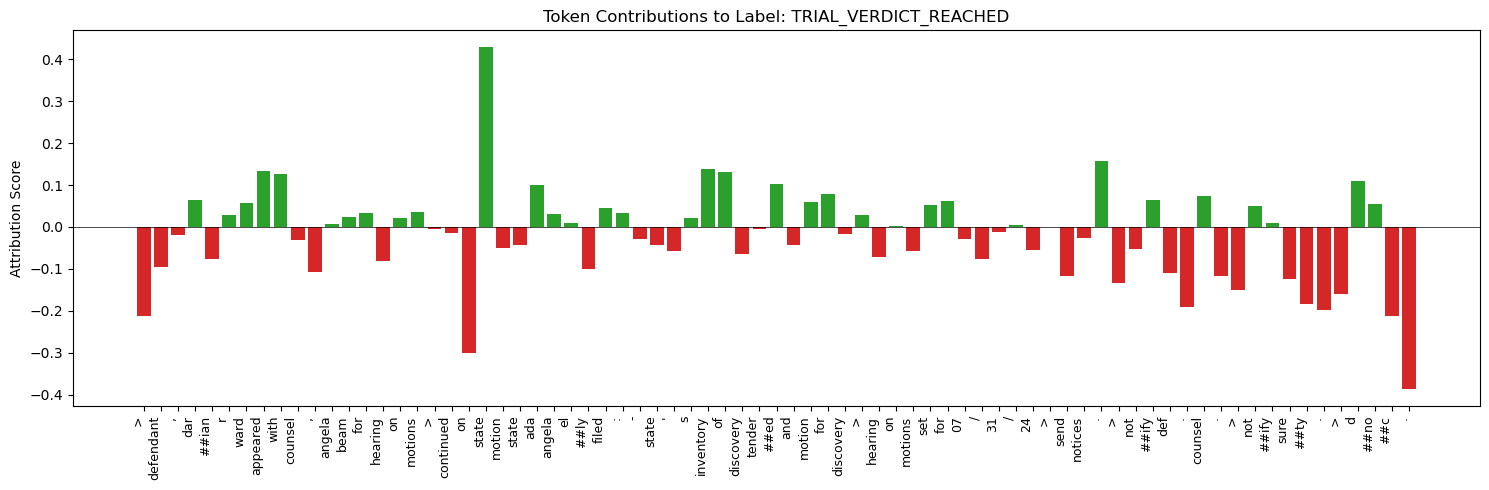

In [ ]:
analyzer.visualize_token_attributions(results)

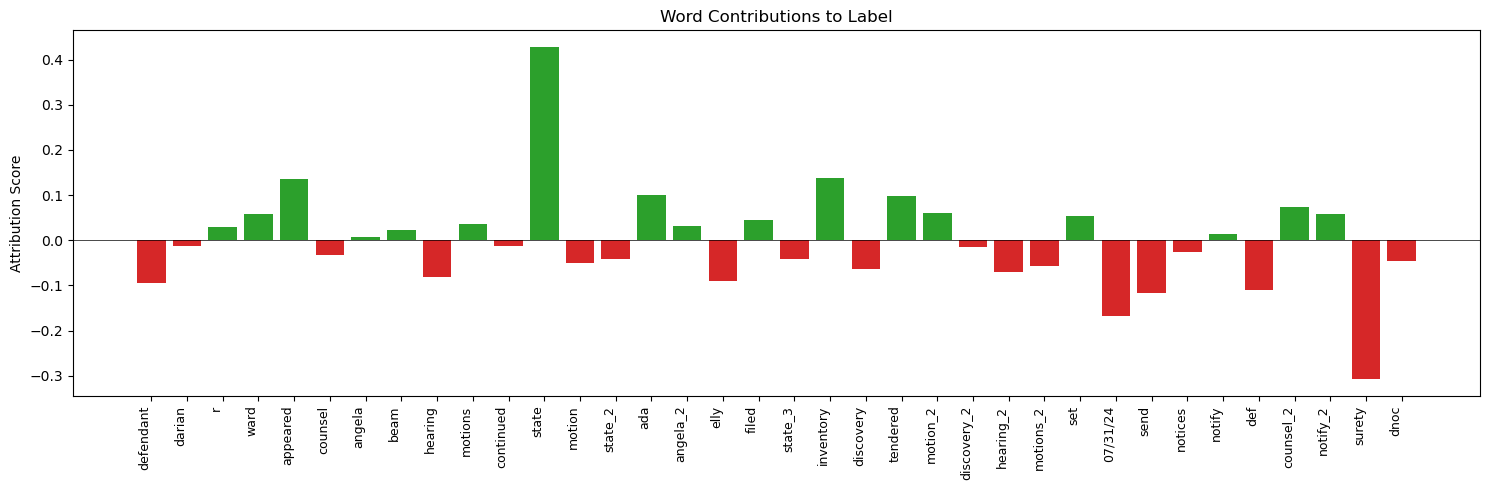

In [ ]:
analyzer.visualize_word_attributions(
    word_importances
)